In [12]:
import warnings; warnings.filterwarnings("ignore")
import joblib
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score)

sns.set_theme(style="whitegrid")
RED, GREEN, BLUE, AMBER = "#B23B32", "#3F8B5D", "#3D5A99", "#B9821E"
FIG_DIR = "../outputs/figures"

df = pd.read_csv("../data/interim/smart_waste_features_v2.csv", parse_dates=["ArrivalDate", "ExpiryDate"])
df = df.sort_values(["ArrivalDate", "BatchID"]).reset_index(drop=True)     # oldest first
print(df.shape)

(572, 23)


#### Three-way split 
A plain "first 600 rows / next 200 / last 200" cuts through batches at the boundaries. The cell below shows how many batches that would leak across, then splits on **batch boundaries** instead. It is still date-ordered.

In [13]:
# What a plain row-based split would do:
n = len(df)
naive_train, naive_val, naive_test = df.iloc[:int(0.6 * n)], df.iloc[int(0.6 * n):int(0.8 * n)], df.iloc[int(0.8 * n):]
print("Batches shared by validation and test  (row split):", len(set(naive_val.BatchID) & set(naive_test.BatchID)))

# Batch-aware split: order batches by first arrival, then fill train until 600 rows, validation until 800, test gets the rest.
batch_order = df.groupby("BatchID").agg(arrival=("ArrivalDate", "min"), rows=("BatchID", "size")).sort_values("arrival")
batch_order["cum_rows"] = batch_order["rows"].cumsum()
batch_order["DataSplit"] = np.where(batch_order["cum_rows"] <= 0.6 * n, "Train",
                             np.where(batch_order["cum_rows"] <= 0.8 * n, "Validation", "Test"))
df["DataSplit"] = df["BatchID"].map(batch_order["DataSplit"])

summary = (df.groupby("DataSplit")
           .agg(rows=("IsSpoiled", "size"), batches=("BatchID", "nunique"), spoiled_batches=("BatchID", lambda s: df.loc[s.index].groupby("BatchID")["IsSpoiled"].first().sum()),
                spoiled_rate=("IsSpoiled", "mean"), first_arrival=("ArrivalDate", "min"), last_arrival=("ArrivalDate", "max"))
           .reindex(["Train", "Validation", "Test"]).round(3))
print(summary)
df.to_csv("../data/interim/smart_waste_split_v2.csv", index=False)     # every row with its DataSplit (used for cut-off justification later)

Batches shared by validation and test  (row split): 1
            rows  batches  spoiled_batches  spoiled_rate first_arrival  \
DataSplit                                                                
Train        325       15               10         0.652    2025-06-12   
Validation   125        6                3         0.472    2025-06-16   
Test         122        7                4         0.500    2025-06-19   

           last_arrival  
DataSplit                
Train        2025-06-16  
Validation   2025-06-19  
Test         2025-06-24  


**Interpretation** 
* The spoiled rate falls across the splits. Recent batches had not yet reached expiry when the data was collected, so their label is still "not spoiled" by default. A date-ordered split cannot fix that. It is a limitation of the dataset, and it means the test set holds very few spoiled batches. This is why a cross-validation check follows.

In [14]:
train = df[df["DataSplit"] == "Train"]
val = df[df["DataSplit"] == "Validation"]
test = df[df["DataSplit"] == "Test"]
dev = df[df["DataSplit"] != "Test"]          # train + validation, used for cross-validation only

#### Preprocessing pipeline
`StandardScaler` puts numbers on the same scale (helps Logistic Regression). `OneHotEncoder` turns text categories into 0/1 columns.
The pipeline learns its scaling and categories from the **training data only** and then applies them unchanged to validation and test. That is another leak prevented.

In [15]:
numeric_features = ["StockQty", "DailySaleAvg", "Total_Shelf_Life_Days", "Stock_Coverage_Ratio", "Sales_vs_Nearby_Gap",
                    "DistanceToNearestStore", "AvgDailySaleInNearbyStores",
                    "OnPromotion", "TemperatureSensitive", "Zone_Missing", "TemperatureSupport_Missing"]
categorical_features = ["Category", "StoreLocation", "Zone", "TemperatureSupport"]
features = numeric_features + categorical_features

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),    # handle_unknown: unseen category -> all zeros, no crash
])

X_train, y_train = train[features], train["IsSpoiled"]
X_val, y_val = val[features], val["IsSpoiled"]
X_test = test[features]

#### Training both models on the Train set only, evaluate on Validation
* **Logistic Regression** 
* **Random Forest** 
* **Naive baseline:** 

In [16]:
logreg = Pipeline([("prep", preprocessor),
                   ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))])
rf = Pipeline([("prep", preprocessor),
               ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                                random_state=42, n_jobs=-1))])
logreg.fit(X_train, y_train)      # fit on TRAIN only
rf.fit(X_train, y_train)

val_probs = {"Logistic Regression": logreg.predict_proba(X_val)[:, 1], "Random Forest": rf.predict_proba(X_val)[:, 1]}
rows = []
for name, p in val_probs.items():
    rows.append({"Model": name,
                 "PR-AUC": round(average_precision_score(y_val, p), 3),
                 "ROC-AUC": round(roc_auc_score(y_val, p), 3),
                 "Precision@0.5": round(precision_score(y_val, p >= 0.5, zero_division=0), 3),
                 "Recall@0.5": round(recall_score(y_val, p >= 0.5), 3),
                 "F1@0.5": round(f1_score(y_val, p >= 0.5), 3)})
rows.append({"Model": "Naive: flag everything", "PR-AUC": round(y_val.mean(), 3), "ROC-AUC": 0.5,
             "Precision@0.5": round(y_val.mean(), 3), "Recall@0.5": 1.0,
             "F1@0.5": round(2 * y_val.mean() / (1 + y_val.mean()), 3)})
val_table = pd.DataFrame(rows)
pd.set_option("display.width", 200); print(val_table)

                    Model  PR-AUC  ROC-AUC  Precision@0.5  Recall@0.5  F1@0.5
0     Logistic Regression   0.322    0.169          0.241       0.237   0.239
1           Random Forest   0.297    0.034          0.394       0.729   0.512
2  Naive: flag everything   0.472    0.500          0.472       1.000   0.641


In [17]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"recall": "recall", "precision": "precision", "f1": "f1", "roc_auc": "roc_auc"}
cv_rows = []
for name, model in [("Logistic Regression", logreg), ("Random Forest", rf)]:
    r = cross_validate(model, dev[features], dev["IsSpoiled"], cv=cv, groups=dev["BatchID"], scoring=scoring)
    cv_rows.append({"Model": name, **{f"{k} mean": round(r[f"test_{k}"].mean(), 2) for k in scoring},
                    **{f"{k} std": round(r[f"test_{k}"].std(), 2) for k in scoring}})
cv_table = pd.DataFrame(cv_rows); print(cv_table)
print("\nA ROC-AUC near 0.5 means no better than a coin flip. A large std means the result depends on which batches landed in which fold.")

                 Model  recall mean  precision mean  f1 mean  roc_auc mean  recall std  precision std  f1 std  roc_auc std
0  Logistic Regression         0.62            0.52     0.57          0.26        0.37           0.33    0.34         0.39
1        Random Forest         0.75            0.77     0.65          0.57        0.34           0.21    0.22         0.26

A ROC-AUC near 0.5 means no better than a coin flip. A large std means the result depends on which batches landed in which fold.


#### Threshold tuning on the Validation set


In [18]:
def best_f1_threshold(y_true, probs):
    precision, recall, thresholds = precision_recall_curve(y_true, probs)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-9)
    i = int(np.argmax(f1))
    return float(thresholds[i]), float(f1[i]), precision, recall, thresholds

thr = {n: best_f1_threshold(y_val, p) for n, p in val_probs.items()}
for n, t in thr.items():
    print(f"{n:20s} threshold = {t[0]:.3f} | validation F1 = {t[1]:.3f}")

# Final model = the one with the higher validation PR-AUC (chosen on validation, never on test).
chosen_name = val_table[val_table["Model"].isin(val_probs)].sort_values("PR-AUC", ascending=False).iloc[0]["Model"]
chosen_model = logreg if chosen_name == "Logistic Regression" else rf
THRESHOLD = thr[chosen_name][0]
print("\nChosen model:", chosen_name, "| threshold:", round(THRESHOLD, 3))

Logistic Regression  threshold = 0.054 | validation F1 = 0.641
Random Forest        threshold = 0.322 | validation F1 = 0.641

Chosen model: Logistic Regression | threshold: 0.054


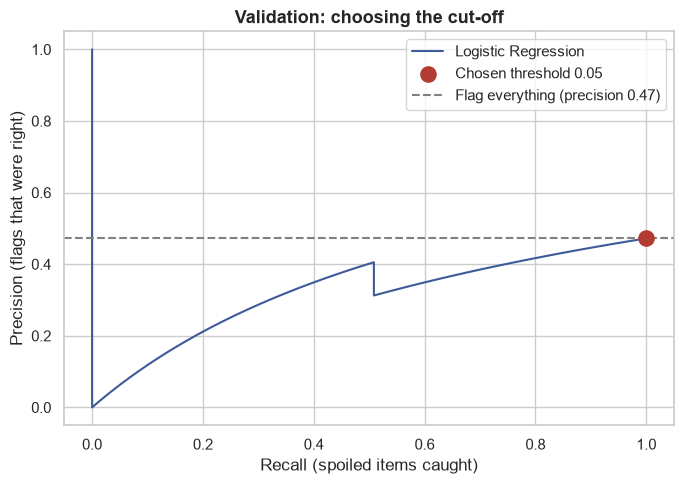

In [19]:
#validation PR curve for the chosen model, with the chosen threshold marked.
_, f1_best, precision, recall, thresholds = thr[chosen_name]
i = int(np.argmin(np.abs(thresholds - THRESHOLD)))
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, color=BLUE, linewidth=1.5, label=f"{chosen_name}")
plt.scatter(recall[i], precision[i], color=RED, s=120, zorder=5, label=f"Chosen threshold {THRESHOLD:.2f}")
plt.axhline(y_val.mean(), color="grey", linestyle="--", label=f"Flag everything (precision {y_val.mean():.2f})")
plt.xlabel("Recall (spoiled items caught)"); plt.ylabel("Precision (flags that were right)")
plt.title("Validation: choosing the cut-off", fontsize=13, weight="bold"); plt.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/model_validation_pr_curve.png", dpi=150); plt.show()

#### Applying the chosen threshold to the Test set and save


In [20]:
test_out = test.copy()
test_out["RF_Prob_Raw"] = rf.predict_proba(X_test)[:, 1]
test_out["LR_Prob"] = logreg.predict_proba(X_test)[:, 1]
test_out["Final_Prob"] = test_out["LR_Prob"] if chosen_name == "Logistic Regression" else test_out["RF_Prob_Raw"]
test_out["Final_Pred"] = (test_out["Final_Prob"] >= THRESHOLD).astype(int)
test_out["Threshold"] = THRESHOLD
test_out["Model_Used"] = chosen_name
test_out["DataSplit"] = "Test"
test_out.to_csv("../data/interim/model_predictions_v2.csv", index=False)

joblib.dump(rf, "../data/interim/random_forest_v2.joblib")
names = rf.named_steps["prep"].get_feature_names_out()
importance = (pd.DataFrame({"Feature": names, "Importance": rf.named_steps["model"].feature_importances_})
              .assign(Feature=lambda d: d["Feature"].str.replace("num__", "", regex=False).str.replace("cat__", "", regex=False))
              .sort_values("Importance", ascending=False))
importance.to_csv("../data/interim/rf_feature_importance_v2.csv", index=False)
print("Saved", len(test_out), "test rows to ../data/interim/model_predictions_v2.csv")

Saved 122 test rows to ../data/interim/model_predictions_v2.csv
